<a href="https://colab.research.google.com/github/ThomasKempf/info_S7/blob/main/Sujet_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Série d'exercices - classification


# 1. Introduction
## Présentation de l'ensemble de données et objectifs de cette série

Dans cette série d'exercices, nous nous allons nous concentrés sur un ensemble de données contenant des informations relatives à la classification des médicaments en se basant sur les données générales des patients ainsi que leurs diagnostics médicaux.

Le défi qui se pose est de développer des modèles d'apprentissage automatique capables de prédire le type de médicament le plus adapté à chaque patient.

Pour cela, nous allons :
1. explorer l'ensemble de données en utilisant différentes techniques de visualisation de données.
2. et, développer divers modèles d'apprentissage automatique capables de prédire le type de médicament, dont la régression logistique linéaire, la machine à vecteurs de support linéaire (SVM), la méthode des k plus proches voisins (k-NN), Naïve Bayes (Catégoriel & Gaussien), ainsi que les arbres de décision et les forêts aléatoires

**Mais, avant de commencer, de quel type de problème s'agit il ? Du supervisé ou du non supervisé ?**



## Description de l'ensemble des données

L'ensemble des données comporte **6 variables**, dont **4 catégorielles (qualitatives)** et **2 continues (quantitatives)**.



<br>

Voici à quoi ressemble la **structure de l'ensemble de données.**


<table style="width:100%">
<thead>
<tr>
<th style="text-align:center; font-weight: bold; font-size:14px">Nom de la variable</th>
<th style="text-align:center; font-weight: bold; font-size:14px">Description</th>
<th style="text-align:center; font-weight: bold; font-size:14px">Exemple de données</th>
</tr>
</thead>
<tbody>
<tr>
<td><b>Age</b></td>
<td>Patient Age</td>
<td>23; 47; ...</td>
</tr>
<tr>
<td><b>Sex</b></td>
<td>Gender of patient <br> (male or female)</td>
<td>F; M; ...</td>
</tr>
<tr>
<td><b>BP</b></td>
<td>Levels of blood pressure <br> (high, normal, or low)</td>
<td>HIGH; NORMAL; LOW; ...</td>
</tr>
<tr>
<td><b>Cholesterol</b></td>
<td>Levels of cholesterol <br> (high or normal)</td>
<td>1.4; 1.3; ...</td>
</tr>
<tr>
<td><b>Na_to_K</b></td>
<td>Sodium to potassium ratio in blood</td>
<td>25.355; 13.093; ...</td>
</tr>
<tr>
<td><b>Drug</b></td>
<td>Type of drug</td>
<td>DrugY; drugC; ...</td>
</tr>
</tbody>
</table>

---


# 2. Importation des bibliothèques
**Importation des bibliothèques** qui seront utilisées dans ce cahier.

*À quoi sert chacune de ces bibliothèques ?*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
import sys
print(sys.executable)  #quel pyhon ?

/usr/bin/python3


In [3]:
import sys
!{sys.executable} -m pip uninstall -y imbalanced-learn scikit-learn

Found existing installation: imbalanced-learn 0.14.2
Uninstalling imbalanced-learn-0.14.2:
  Successfully uninstalled imbalanced-learn-0.14.2
Found existing installation: scikit-learn 1.6.1
Uninstalling scikit-learn-1.6.1:
  Successfully uninstalled scikit-learn-1.6.1


In [4]:
import site, glob, shutil, os
u = site.getusersitepackages()
print("User site:", u)

for pat in [r"\imblearn*", r"\imbalanced_learn*", r"\sklearn*", r"\scikit_learn*"]:
    for d in glob.glob(u + pat):
        print("Removing:", d)
        shutil.rmtree(d, ignore_errors=True)

User site: /root/.local/lib/python3.13/site-packages


In [8]:
import sys
!{sys.executable} -m pip install -U scikit-learn==1.5.1 imbalanced-learn==0.13.0 #ensuite : redémarrer votre environnement !

  Using cached scikit_learn-1.5.1.tar.gz (7.0 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn: filename=scikit_learn-1.5.1-cp313-cp313-linux_x86_64.whl size=12152362 sha256=71418a1cc38fae5600aef8435b093c82d214914af9088d6e5967a53f93a60932
  Stored in directory: /root/.cache/pip/wheels/e2/3f/e6/b9237e0dd0688475370a1b8e4f6247daa3baad6abdaed9fdb9
Successfully built scikit-learn
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.1 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.1 which is incompatible.


In [10]:
import sklearn, imblearn                  #à exécuter apresredémarrage de l'environnement
print("sklearn:", sklearn.__version__)
print("imblearn:", imblearn.__version__)
print("sklearn path:", sklearn.__file__)
print("imblearn path:", imblearn.__file__)

sklearn: 1.5.1
imblearn: 0.13.0
sklearn path: /usr/local/lib/python3.13/dist-packages/sklearn/__init__.py
imblearn path: /usr/local/lib/python3.13/dist-packages/imblearn/__init__.py


# 3. Lecture de l'ensemble des données
**Question 3.1** Après avoir importé les bibliothèques, nous allons également importer **l'ensemble de données** (drug200.csv à télécharger sur Moodle) qui sera utilisé.

Utilisez la fonction appropriée pour importer l'ensemble de données dans la variable df_drug

Complétez le code ci-dessous :


In [21]:
df_drug =

**Question 3.2** Utilisez la fonction appropriée pour afficher les cinq premières lignes de l'ensemble de données.


In [22]:
df_drug.head()


,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


Type de données et vérification des valeurs nulles dans l'ensemble de données.

Utilisez la fonction info()  obtenir des informations sur les types de données.

In [23]:
df_drug.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


**Question 3.3** D'après les résultats ci-dessus, quels types de données sont présents dans l'ensemble de données ?

Y a-t-il des valeurs manquantes/nulles ?

Expliquez vos observations.

On observe un tableau contenant des données sur des individus avec leur âge, sexe et différentes informations.

# 4. Exploration initiale de l'ensemble de données
Cette section permettra d'explorer l'ensemble de données brut qui a été importé.

## 4.1 Variables catégorielles

**Question 4.1.1** Utilisez la fonction value_counts() pour déterminer combien de fois chaque médicament (Drug) apparaît dans l'ensemble de données.

Complétez le code ci-dessous pour obtenir cette information :

In [24]:
df_drug['Drug'].value_counts()


,count
Drug,
drugY,91
drugX,54
drugA,23
drugC,16
drugB,16


**Question 4.1.2** A partir des résultats ci-dessus, quel est le médicament le plus fréquent que les autres types de médicaments ?

Le médicament le plus fréquemment utilisé est la drugY

**Question 4.1.3** En utilisant la meme fonction, value_counts, déterminer la répartition des genres des patients ?
Est-elle équilibrée ?

In [25]:
df_drug['Sex'].value_counts()


,count
Sex,
M,104
F,96


**Question 4.1.4** En utilisant la meme fonction, value_counts, déterminer la répartition de la pression sanguine des patients ?
Est-elle équilibrée ?

In [26]:
df_drug['BP'].value_counts()


,count
BP,
HIGH,77
LOW,64
NORMAL,59


**Question 4.1.** En utilisant la meme fonction, value_counts, déterminer la répartition du cholestérol des patients ?
Est-il équilibré ?

In [29]:
df_drug['Cholesterol'].value_counts()

,count
Cholesterol,
HIGH,103
NORMAL,97


## 4.2 Variables numériques

**Question 4.2.1** Utilisez la fonction describe() pour afficher des statistiques sur les variables numériques dans l'ensemble de données (moyenne, le compte, l'écart-type, le minimum, le maximum, et d'autres).

In [30]:
df_drug.describe()


,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


**Question 4.2.2** Calculez la dissymétrie (skewness) de la variable "Âge" (Age). Complétez le code ci-dessous et affichez la dissymétrie.

In [31]:
skewAge = df_drug['Age'].skew(axis=0, skipna=True)
print('Skewness Age :', skewAge)


Skewness Age : 0.03030835703000607


**Question 4.2.3** Calculez la dissymétrie (skewness) de la variable "Na_to_K" (rapport sodium-potassium). Complétez le code ci-dessous et affichez la dissymétrie.

In [32]:
skewNatoK = df_drug['Na_to_K'].skew(axis=0, skipna=True)
print('Skewness Na_to_K :', skewNatoK)


Skewness Na_to_K : 1.039341186028881


**Question 4.2.4** Utilisez la bibliothèque Seaborn (sns) pour afficher les distributions des variables "Âge" et "Na to K". Complétez le code ci-dessous pour tracer les histogrammes des deux variables :

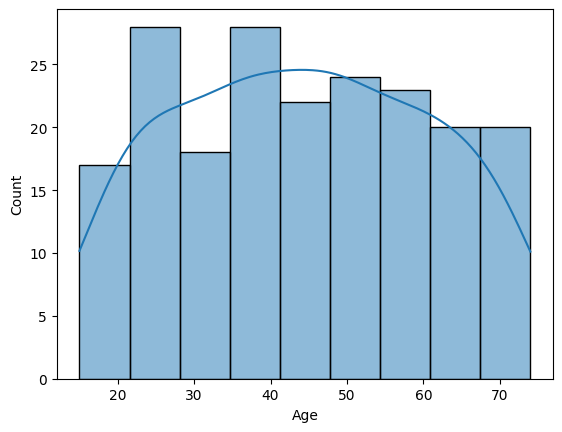

In [33]:
sns.histplot(data=df_drug, x='Age', kde=True)
plt.show()


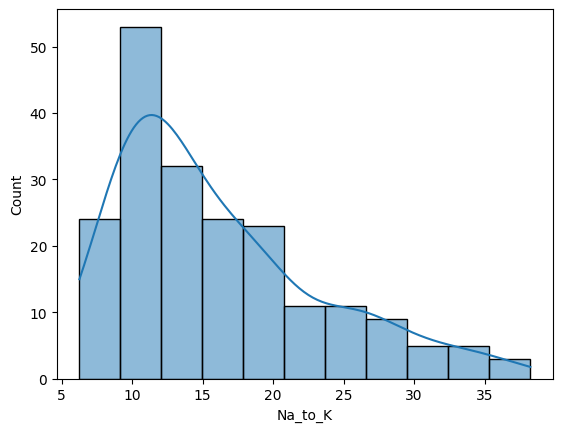

In [34]:
sns.histplot(data=df_drug, x='Na_to_K', kde=True)
plt.show()


**Question 4.2.5** Comment décririez-vous la distribution de la colonne 'Âge' et de la colonne 'Na to K' en examinant les graphiques ?
Comment cela correspond-il aux valeurs de dissymétrie que vous avez calculées  ?

# 5. Analyse exploratoire des données pour l'apprentissage automatique
Cette section explorera les variables de l'ensemble de données en utilisant différents types de graphiques et de diagrammes.

## 5.1 Distribution des types de médicaments

**Question 5.1.1** Utilisez la bibliothèque Seaborn pour afficher la distribution des types de médicaments en utilisant un graphique. Complétez le code ci-dessous pour tracer le graphique :

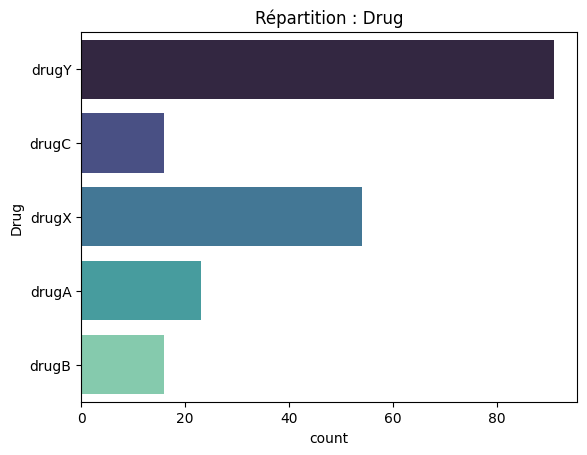

In [35]:
sns.countplot(y='Drug', data=df_drug, hue='Drug', palette='mako', legend=False)
plt.title('Répartition : Drug')
plt.show()


**Question 5.1.2** Comment pouvez-vous interpréter le graphique de distribution des types de médicaments ? Y a-t-il un médicament qui est plus fréquent que les autres ? Expliquez vos observations.

## 5.2 Distribution des genres

**Question 5.2.1** Utilisez la bibliothèque Seaborn pour afficher la distribution des genres en utilisant un graphique. Complétez le code ci-dessous pour tracer le graphique :

In [ ]:
sns.countplot(x='Sex', data=df_drug, hue='Sex', palette='mako', legend=False)
plt.title('Répartition : Sex')
plt.show()


**Question 5.2.2** omment pouvez-vous interpréter le graphique de distribution des genres ? La répartition des genres est-elle équilibrée ? Expliquez vos observations.

Faites de même pour les section 5.3 à 5.7 !

## 5.3 Distribution de la pression sanguine

In [ ]:
sns.set_theme(style="darkgrid")
sns....(y="...", data=df_drug, palette="...")
plt.ylabel('Pression sanguine')
plt.xlabel('Total')
plt.show()

## 5.4 Distribution du cholestérol

In [ ]:
sns.set_theme(style="darkgrid")
sns....(x="...", data=..., palette="...")
plt.xlabel('Cholestérol')
plt.ylabel('Total')
plt....()

## 5.5 Distribution des genres en fonction du type de médicament

**Question 5.5.1** Utilisez la fonction pd.crosstab pour créer un graphique qui montre la distribution des genres en fonction du type de médicament.

In [ ]:
pd....(df_drug....,df_drug....).plot(kind="bar",figsize=(12,5),color=['#003f5c','#ffa600','#58508d','#bc5090','#ff6361'])
plt.title('Distribution des genres en fonction du type de médicament')
plt....('Genre')
plt.xticks(rotation=0)
plt....('Frequence')
plt....()

**Question 5.5.2** Comment pouvez-vous interpréter le graphique de distribution des genres en fonction du type de médicament ? Quelles conclusions pouvez-vous tirer de ce graphique ?

## 5.6 Distribution de la pression sanguine en fonction du cholestérol

**Question 5.6.1** Utilisez la fonction pd.crosstab pour créer un graphique qui montre la distribution de la pression sanguine en fonction du cholestérol.

In [ ]:
pd....(df_drug....,df_drug....)....(kind="bar",figsize=(15,6),color=['#6929c4','#1192e8'])
plt....('Distribution de la pression sanguine en fonction du cholestérol')
plt.xlabel('Pression sanguine')
plt.xticks(rotation=0)
plt.ylabel('Frequence')
plt....()

**Question 5.6.2** Comment pouvez-vous interpréter le graphique de distribution de la pression sanguine en fonction du cholestérol ? Quelles informations pouvez-vous en tirer ?

## 5.7 Distribution du rapport sodium-potassium (NA_to_K) en fonction du genre et de l'âge

**Question 5.7.1** Utilisez les graphiques de dispersion pour montrer la distribution du rapport sodium-potassium (NA_to_K) en fonction du genre et de l'âge.

In [ ]:
plt....(x=df_drug....[df_drug....=='F'], y=df_drug....[(df_drug....=='F')], c="Blue")
plt....(x=df_drug....[df_drug...=='M'], y=df_drug....[(df_drug....=='M')], c="Orange")
plt.legend(["Femelle", "Male"])
plt.xlabel("Age")
plt.ylabel("Na_to_K")
plt....()

**Question 5.7.2**  Que pouvez-vous conclure de ces graphiques de dispersion ? Existe-t-il une corrélation entre l'âge, le rapport sodium-potassium (NA_to_K) et le genre des patients ?

# 6. Preparation de l'ensemble des données
Cette section préparera l'ensemble de données avant de construire les modèles d'apprentissage automatique.

## 6.1 Regroupement des données (Data Binning)

### 6.1.1 Age
**Question 6.1.1.1** Pour regrouper les données d'âge en 7 catégories, complétez le code ci-dessous en spécifiant les intervalles de catégories d'âge et leurs étiquettes :

In [ ]:
bin_age = [0, ..., ..., ..., ..., ..., ..., ...]
category_age = ['...', '...', '...', '...', '...', '...', '...']
df_drug['Age_binned'] = pd.cut(df_drug['Age'], bins=bin_age, labels=category_age)
df_drug = df_drug.drop(['Age'], axis = 1)

**Question 6.1.1.2** Quels sont les intervalles d'âge que vous avez spécifiés pour le regroupement des données ? Combien de catégories d'âge différentes obtenez-vous après le regroupement ? Expliquez l'utilité de cette étape de préparation des données.

### 6.1.2 Rapport sodium-potassium (Na_to_K)

**Question 6.1.2.1** Pour regrouper le rapport sodium-potassium (Na_to_K) en 4 catégories, complétez le code ci-dessous en spécifiant les intervalles de catégories de Na_to_K et leurs étiquettes :

In [ ]:
bin_NatoK = [0, ..., ..., ...., ...]
category_NatoK = ['<...', '...', '....', '...']
df_drug['Na_to_K_binned'] = pd.cut(df_drug['Na_to_K'], bins=bin_NatoK, labels=category_NatoK)
df_drug = df_drug.....(['Na_to_K'], axis = 1)

**Question 6.1.2.2** Quels sont les intervalles que vous avez spécifiés pour le regroupement du rapport sodium-potassium ? Combien de catégories de Na_to_K différentes obtenez-vous après le regroupement ? Pourquoi est-il important de regrouper ces données ?

## 6.2 Répartition de l'ensemble de données
**Question 6.2.1** Pour répartir l'ensemble de données en 70% pour l'entraînement et 30% pour les tests, complétez le code ci-dessous en spécifiant les variables appropriées pour les ensembles d'entraînement et de test :

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
X = df_drug....(["Drug"], axis=1)
y = df_drug["Drug"]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = ...(X, y, test_size = 0.3, random_state = 0)

**Question 6.2.1** Pourquoi est-il important de diviser l'ensemble de données en ensembles d'entraînement et de test ? Quel est le rôle de la graine (random_state) dans cette opération ?

## 6.3 Ingénierie des caractéristiques (Feature Engineering)
**Question 6.3.1** Pour effectuer le codage one-hot des variables catégorielles dans l'ensemble d'entraînement (X_train), complétez le code ci-dessous en utilisant la fonction appropriée pour transformer ces variables catégorielles en une forme adaptée aux algorithmes d'apprentissage automatique :

In [ ]:
X_train = pd.get_dummies(...)

**Question 6.3.2** ourquoi est-il nécessaire de convertir les variables catégorielles en codage one-hot ? Comment cette transformation améliore-t-elle la prédiction des modèles d'apprentissage automatique ?

**Question 6.3.3** Réalisez la même opération de codage one-hot pour l'ensemble de test (X_test) en complétant le code approprié :

In [ ]:
X_test = pd.get_dummies(...)

**Question 6.3.4** Pourquoi est-il important d'appliquer la même transformation de codage one-hot à l'ensemble de test que celle appliquée à l'ensemble d'entraînement ? Quels problèmes cela résout-il ?

In [ ]:
X_train....()

In [ ]:
X_test.head()

## 6.4 Technique SMOTE
**Question 6.4.1** Pourquoi est-il nécessaire d'utiliser la technique SMOTE pour gérer le déséquilibre des classes, en particulier lorsque le nombre de 'DrugY' est supérieur à celui des autres types de médicaments ? Complétez la réponse.


**Question 6.4.2** Complétez le code ci-dessous pour appliquer la technique SMOTE à l'ensemble d'entraînement (X_train et y_train) afin de suréchantillonner les classes sous-représentées :

In [ ]:
from imblearn.over_sampling import SMOTE
X_train, y_train = ...().fit_resample..., ...)

**Question 6.4.2** Une fois que vous avez appliqué la technique SMOTE, quel effet cela a-t-il sur la distribution des types de médicaments, comme le montre le graphique généré ?

Pourquoi est-il important d'obtenir une distribution équilibrée des classes pour l'entraînement des modèles d'apprentissage automatique ?

Remplissez le code suivant pour trouvez la réponse.

In [ ]:
sns.set_theme(style="darkgrid")
sns....(y=y_train, data=..., palette="mako_r")
plt.ylabel('Type de médicament')
plt.xlabel('Total')
plt.show()

# 7. Modèles !

## 7.1 Regression logistique

**Question 7.1.1** Complétez le code ci-dessous pour importer la classe LogisticRegression depuis la bibliothèque sklearn.linear_model, initialiser un modèle de régression logistique avec le solveur 'liblinear' et une limite d'itérations maximales de 5000, puis ajuster le modèle aux données d'entraînement.

In [ ]:
from sklearn.linear_model import LogisticRegression
LRclassifier = LogisticRegression(solver='liblinear', max_iter=5000)
LRclassifier.fit(...)


print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import accuracy_score
LRAcc = accuracy_score(y_pred,y_test)
print('L exactitude (accuracy) de la régression logistique est de : {:.2f}%'.format(LRAcc*100))

**Question 7.1.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle de régression logistique que vous avez ajusté.

In [ ]:
y_pred = LRclassifier.predict(...)

**Question 7.1.3** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle de régression logistique sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
LRAcc = accuracy_score(...,...)
print('L exactitude (accuracy) de la régression logistique est de : {:.2f}%'.format(LRAcc*100))

**Question 7.1.4** Interprétez les résultats. Que pouvez-vous conclure de la performance du modèle de régression logistique ? Quels sont les principaux indicateurs de performance que vous avez examinés ?

## 7.2 K plus proches voisins
**Question 7.2.1** Complétez le code ci-dessous pour importer la classe KNeighborsClassifier depuis la bibliothèque sklearn.neighbors, initialiser un modèle de K plus proches voisins avec un nombre de voisins (n_neighbors) égal à 20, puis ajuster le modèle aux données d'entraînement.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
KNclassifier = KNeighborsClassifier(n_neighbors=20)
KNclassifier.fit(X...,...)

**Question 7.2.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle de K plus proches voisins que vous avez ajusté.

In [ ]:
y_pred = KNclassifier.predict(...)

**Question 7.2.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle de K plus proches voisins sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...)
print(...(..., ...))

**Question 7.2.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle de K plus proches voisins sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
KNAcc = accuracy_score(...,...)
print('L exactitude (accuracy) des K Plus Proches Voisins est de : {:.2f}%'.format(KNAcc*100))

**Question 7.2.5** Complétez le code pour créer une liste scoreListknn qui enregistre les scores (exactitudes) du modèle de K plus proches voisins pour différentes valeurs de n_neighbors de 1 à 29.

In [ ]:
scoreListknn = []
for i in range(1,30):
    KNclassifier = KNeighborsClassifier(n_neighbors = ...)
    KNclassifier.fit(..., ...)
    scoreListknn.append(KNclassifier.score(..., ...))



**Question 7.2.6** Complétez le code pour tracer un graphique montrant la relation entre les valeurs de n_neighbors et les scores (exactitudes) du modèle de K plus proches voisins.

In [ ]:
plt.plot(range(1,30), scoreListknn)
plt.xticks(np....(1,30,1))
plt.xlabel("K value")
plt.ylabel("Score")
plt....()

**Question 7.2.7** Quelle est la valeur optimale de n_neighbors qui maximise l'exactitude du modèle K plus proches voisins ? Comment pouvez-vous choisir la meilleure valeur de n_neighbors pour ce modèle ?
Complétez le code suivant :

In [ ]:
KNAccMax = max(scoreListknn)
print("KNN Acc Max {:.2f}%".format(KNAccMax*100))

## 7.3 Support Vector Machine (SVM)

**Question 7.3.1** Complétez le code ci-dessous pour importer la classe SVC depuis la bibliothèque sklearn.svm, initialiser un modèle SVM avec un noyau linéaire et une limite d'itérations maximales de 251, puis ajuster le modèle aux données d'entraînement.

In [ ]:
from sklearn.svm import SVC
SVCclassifier = SVC(kernel='linear', max_iter=251)
SVCclassifier.fit(..., ...)

**Question 7.3.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle SVM que vous avez ajusté.

In [ ]:
y_pred = SVCclassifier.predict(...)

**Question 7.3.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle SVM sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...))
print(...(..., ...))

**Question 7.3.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle SVM sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
SVCAcc = accuracy_score(...,...)
print('L exactiture (accuracy) du SVM est de : {:.2f}%'.format(SVCAcc*100))

**Question 7.3.5** Interprétez les résultats. Que pouvez-vous conclure de la performance du modèle SVM avec un noyau linéaire ? Quels sont les principaux indicateurs de performance que vous avez examinés ?

## 7.4 Naive Bayes
### 7.4.1 Categorical NB
**Question 7.4.1.1** Complétez le code ci-dessous pour importer la classe CategoricalNB depuis la bibliothèque sklearn.naive_bayes, initialiser un modèle Naive Bayes catégoriel, puis ajuster le modèle aux données d'entraînement.

In [ ]:
from sklearn.naive_bayes import CategoricalNB
NBclassifier1 = CategoricalNB()
NBclassifier1.fit(..., ...)

**Question 7.4.1.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle Naive Bayes catégoriel que vous avez ajusté.

In [ ]:
y_pred = NBclassifier1.predict(...)

**Question 7.4.1.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle Naive Bayes catégoriel sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...))
print(...(..., ...))


**Question 7.4.1.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle Naive Bayes catégoriel sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
NBAcc1 = accuracy_score(...,...)
print('L exactitude (accuracy) du Naive Bayes est de : {:.2f}%'....(NBAcc1*100))

**Question 7.4.1.5** Interprétez les résultats. Que pouvez-vous conclure de la performance du modèle Naive Bayes catégoriel ? Quels sont les principaux indicateurs de performance que vous avez examinés ?

### 7.4.2 Gaussian NB
**Question 7.4.2.1**

In [ ]:
from sklearn.naive_bayes import GaussianNB
NBclassifier2 = GaussianNB()
NBclassifier2.fit(X_train, y_train)

**Question 7.4.2.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle Naive Bayes gaussien que vous avez ajusté.

In [ ]:
y_pred = NBclassifier2.predict(...)

**Question 7.4.2.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle Naive Bayes gaussien sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...))
print(confusion_matrix(..., ...))

**Question 7.4.2.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle Naive Bayes gaussien sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
NBAcc2 = accuracy_score(...,...)
print('L exactitude (accuracy) du Gaussian Naive Bayes est de : {:.2f}%'.format(NBAcc2*100))

**Question 7.4.2.5** Interprétez les résultats. Que pouvez-vous conclure de la performance du modèle Naive Bayes gaussien ? Quels sont les principaux indicateurs de performance que vous avez examinés ?

## 7.5 Arbre de décision (Decision Tree)

**Question 7.5.1** Complétez le code ci-dessous pour importer la classe DecisionTreeClassifier depuis la bibliothèque sklearn.tree, initialiser un modèle d'arbre de décision avec un nombre maximum de feuilles (max_leaf_nodes) égal à 20, puis ajuster le modèle aux données d'entraînement.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
DTclassifier = DecisionTreeClassifier(max_leaf_nodes=20)
DTclassifier.fit(X_train, y_train)

**Question 7.5.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle d'arbre de décision que vous avez ajusté.

In [ ]:
y_pred = DTclassifier.predict(...)

**Question 7.5.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle d'arbre de décision sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...))
print(confusion_matrix(..., ...))

**Question 7.5.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle d'arbre de décision sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
DTAcc = accuracy_score(...,...)
print('L exactitude (accuracy) de l arbre de décision est de : {:.2f}%'.format(DTAcc*100))

**Question 7.5.5** Complétez le code pour créer une liste scoreListDT qui enregistre les scores (exactitudes) du modèle d'arbre de décision pour différentes valeurs de max_leaf_nodes de 2 à 49.

In [ ]:
scoreListDT = []
for i in range(2,50):
    DTclassifier = DecisionTreeClassifier(max_leaf_nodes=...)
    DTclassifier.fit(..., ...)
    scoreListDT.append(DTclassifier.score(..., ...))

**Question 7.5.6** Complétez le code pour tracer un graphique montrant la relation entre les valeurs de max_leaf_nodes et les scores (exactitudes) du modèle d'arbre de décision.

In [ ]:
plt.plot(range(2,50), scoreListDT)
plt.xticks(np....(2,50,5))
plt.xlabel("Leaf")
plt.ylabel("Score")
plt....()
DTAccMax = max(scoreListDT)
print("DT Acc Max {:.2f}%".format(DTAccMax*100))

**Question 7.5.7** Quelle est la valeur optimale de max_leaf_nodes qui maximise l'exactitude du modèle d'arbre de décision ? Comment pouvez-vous choisir la meilleure valeur de max_leaf_nodes pour ce modèle ?

## 7.6 Random Forest

**Question 7.6.1**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

RFclassifier = RandomForestClassifier(max_leaf_nodes=30)
RFclassifier.fit(X_train, y_train)

**Question 7.6.2** Complétez le code pour faire des prédictions sur l'ensemble de test (X_test) en utilisant le modèle Random Forest que vous avez ajusté.

In [ ]:
y_pred = RFclassifier.predict(...)

**Question 7.6.3** Complétez le code pour afficher un rapport de classification (classification_report) et une matrice de confusion (confusion_matrix) pour évaluer les performances du modèle Random Forest sur l'ensemble de test.

In [ ]:
print(classification_report(..., ...))
print(...(..., ...))

**Question 7.6.4** Complétez le code pour calculer et afficher l'exactitude (accuracy) du modèle Random Forest sur l'ensemble de test.

In [ ]:
from sklearn.metrics import accuracy_score
RFAcc = accuracy_score(...,...)
print('L exactitude (accuracy) du Random Forest est de : {:.2f}%'.format(RFAcc*100))

**Question 7.6.5**  Complétez le code pour créer une liste scoreListRF qui enregistre les scores (exactitudes) du modèle Random Forest pour différentes valeurs de max_leaf_nodes de 2 à 49.

In [ ]:
scoreListRF = []
for i in range(2,50):
    RFclassifier = RandomForestClassifier(n_estimators = 1000, random_state = 1, max_leaf_nodes=...)
    RFclassifier.fit(..., ...)
    scoreListRF.append(....score(...))

**Question 7.6.6** Complétez le code pour tracer un graphique montrant la relation entre les valeurs de max_leaf_nodes et les scores (exactitudes) du modèle Random Forest.

In [ ]:
plt....(range(2,50), scoreListRF)
plt.xticks(np.arange(2,50,5))
plt.xlabel("RF Value")
plt.ylabel("Score")
plt....()
RFAccMax = max(...)
print("RF Acc Max {:.2f}%".format(RFAccMax*100))

**Question 7.6.7** Quelle est la valeur optimale de max_leaf_nodes qui maximise l'exactitude du modèle Random Forest ?

Comment pouvez-vous choisir la meilleure valeur de max_leaf_nodes pour ce modèle ?

# 8. Comparison des modèles

**Question 8.1** Quels sont les modèles d'apprentissage automatique que vous avez comparés dans cette section ?


**Question 8.2** Quel est l'indicateur de performance utilisé pour comparer les modèles dans le tableau compare ?


**Question 8.3** Quel modèle a obtenu la meilleure précision (accuracy) parmi ceux que vous avez comparés ? Quelle est cette précision ?


**Question 8.4** Quel modèle a obtenu la deuxième meilleure précision (accuracy) ? Quelle est cette précision ?


**Question 8.5** Selon les résultats du tableau compare, quelles sont les performances relatives des modèles en termes de précision ? Quels modèles sont les plus performants et les moins performants ?



**Question 8.6** Si vous deviez choisir un modèle pour prédire la classification du type de médicament, quel modèle choisiriez-vous en fonction des performances observées ?


In [ ]:
compare = pd.DataFrame({'Modèle': ['Logistic Regression', 'K Neighbors', 'K Neighbors Max', 'SVM', 'Categorical NB', 'Gaussian NB', 'Decision Tree', 'Decision Tree Max', 'Random Forest', 'Random Forest Max'],
                        'Précision/Accuracy': [...*100, ...*100, ...*100, ...*100, ...*100, ...*100, ...*100, ...*100, ...*100, ...*100]})
compare....(by='Précision/Accuracy', ascending=...)

# 9. Résultats
La prochaine étape consistera à générer les résultats en un fichier CSV.

## 9.1 Transformation des prédictions dans un format de sortie approprié

**Question 9.1.1** Complétez le code ci-dessous pour transformer les prédictions (pred_lr) en un DataFrame (prediction) contenant les caractéristiques pertinentes. Les caractéristiques incluent 'Sex_F', 'Sex_M', 'BP_HIGH', 'BP_LOW', 'BP_NORMAL', 'Cholesterol_HIGH', 'Cholesterol_NORMAL', 'Age_binned_<20s', 'Age_binned_20s', 'Age_binned_30s', 'Age_binned_40s', 'Age_binned_50s', 'Age_binned_60s', 'Age_binned_>60s', 'Na_to_K_binned_<10', 'Na_to_K_binned_10-20', 'Na_to_K_binned_20-30', 'Na_to_K_binned_>30', et 'DrugType'.

In [ ]:
pred_lr = NBclassifier1.predict(...)
prediction = pd.DataFrame({'Sex_F': ....loc[:,"Sex_F"],
                           'Sex_M': ....loc[:,"Sex_M"],
                           'BP_HIGH': ....loc[:,"BP_HIGH"],
                           'BP_LOW': .....loc[:,"BP_LOW"],
                           'BP_NORMAL': ....loc[:,"BP_NORMAL"],
                           'Cholesterol_HIGH': ....loc[:,"Cholesterol_HIGH"],
                           'Cholesterol_NORMAL': ....loc[:,"Cholesterol_NORMAL"],
                           'Age_binned_<20s': .....loc[:,"Age_binned_<20s"],
                           'Age_binned_20s': .....loc[:,"Age_binned_20s"],
                           'Age_binned_30s': .....loc[:,"Age_binned_30s"],
                           'Age_binned_40s': .....loc[:,"Age_binned_40s"],
                           'Age_binned_50s': ....loc[:,"Age_binned_50s"],
                           'Age_binned_60s': ....loc[:,"Age_binned_60s"],
                           'Age_binned_>60s': ....loc[:,"Age_binned_>60s"],
                           'Na_to_K_binned_<10': ....loc[:,"Na_to_K_binned_<10"],
                           'Na_to_K_binned_10-20': ....loc[:,"Na_to_K_binned_10-20"],
                           'Na_to_K_binned_20-30': ....loc[:,"Na_to_K_binned_20-30"],
                           'Na_to_K_binned_>30': ....loc[:,"Na_to_K_binned_>30"],'DrugType': ...})

**Question 9.1.2** Complétez le code pour effectuer des remplacements pour les colonnes Sex_F, BP_HIGH, BP_LOW, BP_NORMAL, Cholesterol_HIGH, Age_binned_<20s, Age_binned_20s, Age_binned_30s, Age_binned_40s, Age_binned_50s, Age_binned_60s, Age_binned_>60s, Na_to_K_binned_<10, Na_to_K_binned_10-20, Na_to_K_binned_20-30, Na_to_K_binned_>30 en utilisant les valeurs appropriées. Ces colonnes sont définies comme des variables catégorielles.

In [ ]:
# Sex
prediction['Sex_F'] = ...['Sex_F']....([1, 0],['Female', 'Male'])

#BP
prediction['BP_HIGH'] = ...['BP_HIGH']....([1, 0],['High',''])
prediction['BP_LOW'] = ...['BP_LOW']....([1, 0],['Low', ''])
prediction['BP_NORMAL'] = ...['BP_NORMAL']....([1, 0],['Normal', ''])

prediction['BP_HIGH'] = np.where((...['BP_HIGH'] == ''), ...['BP_LOW'], ...['BP_HIGH'])
prediction['BP_HIGH'] = np.where((...['BP_HIGH'] == ''), ...['BP_NORMAL'], ...['BP_HIGH'])

#Cholestrol
prediction['Cholesterol_HIGH'] = ...['Cholesterol_HIGH'].replace([1, 0],['High', 'Normal'])

#Age_binned
prediction['Age_binned_<20s'] = ...['Age_binned_<20s'].replace([1, 0],['<20s',''])
prediction['Age_binned_20s'] = ...['Age_binned_20s'].replace([1, 0],['20s',''])
prediction['Age_binned_30s'] = ...['Age_binned_30s'].replace([1, 0],['30s',''])
prediction['Age_binned_40s'] = ...['Age_binned_40s'].replace([1, 0],['40s',''])
prediction['Age_binned_50s'] = ...['Age_binned_50s'].replace([1, 0],['50s',''])
prediction['Age_binned_60s'] = ...['Age_binned_60s'].replace([1, 0],['60s',''])
prediction['Age_binned_>60s'] = ...['Age_binned_>60s'].replace([1, 0],['>60s',''])

prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_20s'], prediction['Age_binned_<20s'])
prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_30s'], prediction['Age_binned_<20s'])
prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_40s'], prediction['Age_binned_<20s'])
prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_50s'], prediction['Age_binned_<20s'])
prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_60s'], prediction['Age_binned_<20s'])
prediction['Age_binned_<20s'] = np.where((...['Age_binned_<20s'] == ''), prediction['Age_binned_>60s'], prediction['Age_binned_<20s'])

#Na to K
prediction['Na_to_K_binned_<10'] = prediction['Na_to_K_binned_<10']....([1, 0],['<10',''])
prediction['Na_to_K_binned_10-20'] = prediction['Na_to_K_binned_10-20']....([1, 0],['10-20',''])
prediction['Na_to_K_binned_20-30'] = prediction['Na_to_K_binned_20-30']....([1, 0],['20-30',''])
prediction['Na_to_K_binned_>30'] = prediction['Na_to_K_binned_>30']....([1, 0],['>30s',''])

prediction['Na_to_K_binned_<10'] = np.where((prediction['Na_to_K_binned_<10'] == ''), ...['Na_to_K_binned_10-20'], prediction['Na_to_K_binned_<10'])
prediction['Na_to_K_binned_<10'] = np.where((prediction['Na_to_K_binned_<10'] == ''), ...['Na_to_K_binned_20-30'], prediction['Na_to_K_binned_<10'])
prediction['Na_to_K_binned_<10'] = np.where((prediction['Na_to_K_binned_<10'] == ''), ...['Na_to_K_binned_>30'], prediction['Na_to_K_binned_<10'])


**Question 9.1.3** Complétez le code pour supprimer les colonnes inutiles du DataFrame prediction en utilisant la méthode drop.

In [ ]:

# Drop columns
prediction = prediction....(['Sex_M', 'BP_LOW', 'BP_NORMAL', 'Cholesterol_NORMAL', 'Age_binned_20s', 'Age_binned_30s',
                 'Age_binned_40s', 'Age_binned_50s', 'Age_binned_60s', 'Age_binned_>60s',
                'Na_to_K_binned_10-20', 'Na_to_K_binned_20-30', 'Na_to_K_binned_>30'], axis = 1)

**Question 9.1.4** Complétez le code pour renommer les colonnes du DataFrame prediction en utilisant le dictionnaire new_name.

In [ ]:
# Rename columns name
new_name = {'Sex_F': 'Sex', 'BP_HIGH': 'BP', 'Cholesterol_HIGH': 'Cholesterol', 'Age_binned_<20s': 'Age_binned',
          'Na_to_K_binned_<10': 'Na_to_K_binned'}
prediction....(columns=new_name, inplace=...)

## 9.2 Génération du fichier de sortie (CSV)
**Question 9.2.1** Complétez le code ci-dessous pour générer un fichier CSV à partir du DataFrame prediction. Le fichier CSV doit être nommé 'prediction.csv' et vous devez spécifier index=False pour ne pas inclure les index dans le fichier de sortie.

In [ ]:
prediction....('prediction.csv', index=False)
predictioncsv = pd.read_csv('./...')
predictioncsv.head()